---
title: "3.7.c Dengue: brotes y pronóstico"
short_title: "c. Riesgo"
subtitle: "Canal endémico, años de brote y pronóstico a 1, 3 y 6 meses con información hidroclimática"
description: "Evaluación de brotes de dengue en Leticia y réplica del pronóstico hidroclimático de Beal et al. (2025)."
keywords: [dengue, brotes, pronóstico, alerta temprana, subestacional, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/37_dengue/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El riesgo de dengue se mide en **brotes**: meses en que los casos superan lo esperado y saturan la atención en
salud. Beal et al. construyeron modelos estadísticos de pronóstico del dengue a 1, 3 y 6 meses para cuatro ciudades
de Colombia, **entre ellas Leticia**, y encontraron que los modelos con información hidroclimática superaban a los
autorregresivos a 3 y 6 meses, con la TSM como mejor predictor [@beal2025dengue]. Este cuaderno replica esa
comparación con los datos públicos de OpenDengue.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, salud, viz
from leticia.config import parametros

pdg = parametros()["dengue"]
semanal = fuentes.dengue_opendengue()
mensual = salud.casos_mensuales(semanal)

## 1. Canal endémico y años de brote

**Meses por año sobre el percentil 75 de 2011–2018:** 2011: 5, 2012: 5, 2013: 4, 2014: 7, 2015: 3, 2016: 0, 2017: 0, 2018: 0, 2019: 12, 2020: 3, 2021: 3, 2022: 7.

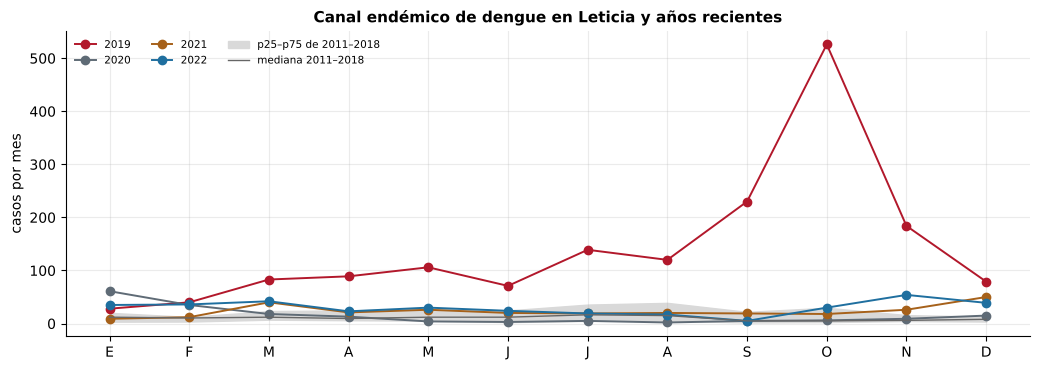

In [3]:
cas = mensual.loc["2011":]
hist = cas.loc[:"2018"]
canal = hist.groupby(hist.index.month).quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots(figsize=(10.5, 3.8))
for anio, color in ((2019, viz.ROJO), (2020, viz.GRIS), (2021, viz.TIERRA), (2022, viz.AZUL_RIO)):
    s = cas[cas.index.year == anio]
    ax.plot(s.index.month, s, "o-", color=color, lw=1.4, label=str(anio))
ax.fill_between(canal.index, canal[0.25], canal[0.75], color="0.85", label="p25–p75 de 2011–2018")
ax.plot(canal.index, canal[0.5], color="0.4", lw=1, label="mediana 2011–2018")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_ylabel("casos por mes")
ax.set_title("Canal endémico de dengue en Leticia y años recientes")
ax.legend(ncol=3, fontsize=7.5)
fig.tight_layout()
sobre = (cas > canal[0.75].reindex(cas.index.month).to_numpy())
display(Markdown("**Meses por año sobre el percentil 75 de 2011–2018:** " + ", ".join(f"{a}: {int(v)}" for a, v in sobre.groupby(sobre.index.year).sum().items()) + "."))

In [4]:
viz.pie(viz.nota_fuente("dengue_opendengue"))

*Fuente: OpenDengue (Clarke et al., 2024) con datos del SIVIGILA – Instituto Nacional de Salud — OpenDengue V1.3, extracto espacial (Colombia a nivel municipal, semanal).*

El canal endémico compara cada mes con la distribución de los años previos, como lo hace la vigilancia en salud
pública. El brote de **2019**, el mayor de la serie, superó el percentil 75 de los años previos los doce meses. Leticia comparte la
transmisión con Tabatinga (Brasil) y Santa Rosa (Perú): sin datos de los tres lados, la vigilancia de un solo país
ve una parte del brote.

## 2. Pronóstico a 1, 3 y 6 meses (réplica de Beal et al.)

In [5]:
era = fuentes.clima_diario()
X = salud.predictores_mensuales(era, {"ONI": fuentes.oni(), "TNA": fuentes.indice_tna()}, base=(1991, 2020))
tablas, predicciones = {}, {}
for r in pdg["rezagos_meses"]:
    tablas[r], predicciones[r] = salud.modelos_dengue(cas, X, r)
hab = pd.concat({f"{r} meses": t["habilidad"] for r, t in tablas.items()}, axis=1)
cor = pd.concat({f"{r} meses": t["r"] for r, t in tablas.items()}, axis=1)
display(Markdown("**Habilidad frente a la climatología (1 − ECM/ECM de la climatología; positivo = mejora), validación dejando un año fuera:**"))
display(hab.round(2))
display(Markdown("**Correlación entre pronóstico y observación (escala log):**"))
display(cor.round(2))

**Habilidad frente a la climatología (1 − ECM/ECM de la climatología; positivo = mejora), validación dejando un año fuera:**

,1 meses,3 meses,6 meses
climatología,0.00,0.00,0.00
autorregresivo,0.76,0.35,-0.01
oceánico,-0.16,-0.16,-0.09
hidroclimático,-0.18,-0.18,-0.13
combinado,0.74,0.25,-0.15


**Correlación entre pronóstico y observación (escala log):**

,1 meses,3 meses,6 meses
climatología,-0.61,-0.67,-0.53
autorregresivo,0.84,0.50,-0.17
oceánico,-0.68,-0.75,-0.23
hidroclimático,-0.42,-0.46,-0.24
combinado,0.84,0.41,-0.08


La habilidad compara cada modelo con la climatología validada de la misma forma. La correlación de la climatología
es negativa por un efecto de la validación: al dejar fuera un año, el promedio mensual se calcula sin él, de modo
que los años con muchos casos reciben un pronóstico más bajo y los años con pocos, uno más alto.

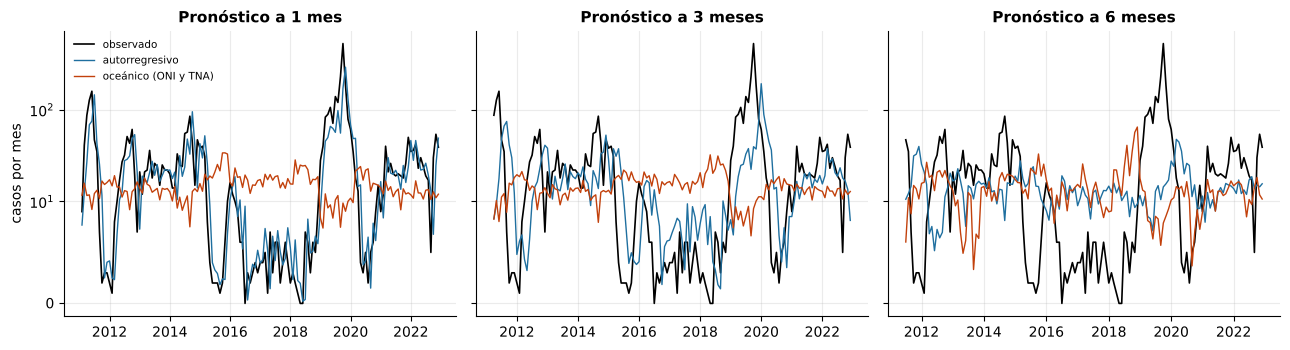

In [6]:
fig, ax = plt.subplots(1, len(predicciones), figsize=(13, 3.6), sharey=True)
for a, (r, p) in zip(ax, predicciones.items()):
    a.plot(p.index, p["observado"], color="k", lw=1.2, label="observado")
    a.plot(p.index, p["autorregresivo"], color=viz.AZUL_RIO, lw=1, label="autorregresivo")
    a.plot(p.index, p["oceánico"], color=viz.CALOR, lw=1, label="oceánico (ONI y TNA)")
    a.set_yscale("symlog", linthresh=10)
    a.set_title(f"Pronóstico a {r} {'mes' if r == 1 else 'meses'}")
ax[0].set_ylabel("casos por mes")
ax[0].legend(fontsize=7.5)
fig.tight_layout()

In [7]:
viz.pie(viz.nota_fuente("dengue_opendengue", "clima_diario", "indices_oceanicos", "indice_tna")
        + " Modelos lineales de log(1 + casos) con ciclo estacional; predicciones de validación cruzada.")

*Fuente: OpenDengue (Clarke et al., 2024) con datos del SIVIGILA – Instituto Nacional de Salud — OpenDengue V1.3, extracto espacial (Colombia a nivel municipal, semanal); ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°; NOAA Climate Prediction Center — ONI (ERSSTv5), trimestres móviles 1950–presente; NOAA Physical Sciences Laboratory — TNA mensual (HadISST1.1, climatología 1991–2020), 1948–presente. Modelos lineales de log(1 + casos) con ciclo estacional; predicciones de validación cruzada.*

**Lectura.** Con los datos públicos de 2011–2022 y modelos lineales simples, **no se reproduce** la habilidad
hidroclimática que Beal et al. reportan a 3 y 6 meses. El modelo autorregresivo, que solo usa los casos recientes,
es muy útil a un mes, conserva habilidad a tres y la pierde a seis; los modelos con temperatura, lluvia, humedad o
TSM no mejoran la climatología a ningún horizonte. Las diferencias pueden venir del periodo, de la selección de
predictores, de la forma del modelo y de la validación, y del peso del brote de 2019 en una serie corta. La lección práctica es doble: para la alerta inmediata conviene vigilar la **tendencia de los casos**,
semana a semana; y un pronóstico climático a 3–6 meses para Leticia exige un trabajo de modelación específico,
validado como en este cuaderno, antes de usarse para decidir.

:::{important} De la vigilancia a la alerta
Las medidas que reducen el riesgo son conocidas: control de criaderos en tanques y recipientes, que aumentan cuando
se almacena agua, por ejemplo durante los racionamientos de las vaciantes ([3.2](../32_sequia/index.md)), vigilancia
entomológica y comunicación con Tabatinga y Santa Rosa. El valor de un pronóstico está en **adelantarlas**: alistar insumos y personal unas
semanas antes del pico de casos.
:::